# MediTrack · Detección de la toma de medicamento con un modelo CNN-LSTM

**Objetivo:** entrenar y evaluar un modelo **CNN-LSTM** que reconozca, a partir del acelerómetro y el giroscopio de un
smartwatch, si una persona **tomó su pastilla**. Después, usar la probabilidad del modelo dentro de la **fusión de
evidencias** de MediTrack (la fórmula del documento técnico) y ver qué decisiones tomaría el sistema.

**Datos:** *DoseMate* (Nzeyimana et al., CHIL 2024, PMLR 248:566–581), el estudio en vida real con relojes Wear OS.
Repositorio público: <https://gitlab.com/umass-smelt-lab/dosemate>. El repositorio **no declara una licencia**: aquí
se usa con fines académicos, citando la fuente, y **no se redistribuyen los datos**. El notebook los descarga del
repositorio original a la carpeta `datos_dosemate/`.

**Secciones**
1. Preparación: librerías, semillas y descarga de los datos
2. Carga segura de los archivos `.pickle`
3. Exploración de los datos
4. Segmentación de eventos (replicando el preprocesamiento del artículo)
5. Modelo CNN-LSTM
6. Evaluación: partición aleatoria y *leave-one-subject-out* (LOSO)
7. Comparación con una línea base y con lo publicado
8. Fusión de evidencias de MediTrack
9. Conclusiones

## 1. Preparación
En Google Colab no hay que instalar nada (ya trae TensorFlow, scikit-learn y SciPy). En otra computadora:
`pip install tensorflow scikit-learn scipy pandas matplotlib`.

In [1]:
# %pip install -q tensorflow scikit-learn scipy pandas matplotlib   # solo si falta algo fuera de Colab

import os, pickle, time, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score, recall_score,
                             confusion_matrix, roc_curve)
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # oculta mensajes internos de TensorFlow
warnings.filterwarnings("ignore")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel("ERROR")

SEMILLA = 42
np.random.seed(SEMILLA)
keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()   # resultados reproducibles
print("TensorFlow", tf.__version__, "· Keras", keras.__version__, "· pandas", pd.__version__)

I0000 00:00:1795680757.632048    6606 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 · Keras 3.15.1 · pandas 3.0.5


I0000 00:00:1795680758.751806    6606 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Descarga de los 19 archivos de usuario (unos 100 MB). Si ya están en la carpeta, no se vuelven a descargar.
URL = "https://gitlab.com/umass-smelt-lab/dosemate/-/raw/main/data-release-1.0/clean/"
USUARIOS = ["user0004", "user002", "user003", "user004", "user008", "user009", "user012", "user014", "user015",
            "user023", "user025", "user027", "user029", "user030", "user031", "user032", "user034", "user2001", "user2002"]
CARPETA = "datos_dosemate"
os.makedirs(CARPETA, exist_ok=True)
for u in USUARIOS:
    destino = os.path.join(CARPETA, f"data_clean_{u}.pickle")
    if not os.path.exists(destino):
        urllib.request.urlretrieve(URL + f"data_clean_{u}.pickle", destino)
print(len(os.listdir(CARPETA)), "archivos ·", round(sum(os.path.getsize(os.path.join(CARPETA, f)) for f in os.listdir(CARPETA)) / 1e6, 1), "MB")

19 archivos · 108.3 MB


## 2. Carga segura de los archivos
Los datos vienen como `pickle` de pandas. Un `pickle` puede **ejecutar código** al abrirse, así que no se usa
`pickle.load` directo: este lector solo permite las clases de pandas y numpy que forman un DataFrame. Además usa el
lector de compatibilidad de pandas, porque los archivos se guardaron con una versión antigua (pandas 1.x).

In [3]:
from pandas.compat import pickle_compat

PERMITIDOS = {
    ("builtins", "slice"), ("functools", "partial"),
    ("numpy", "ndarray"), ("numpy", "dtype"),
    ("numpy.core.multiarray", "_reconstruct"), ("numpy._core.multiarray", "_reconstruct"),
    ("pandas.core.frame", "DataFrame"), ("pandas.core.internals.managers", "BlockManager"),
    ("pandas.core.internals.blocks", "new_block"), ("pandas.core.indexes.base", "_new_Index"),
    ("pandas.core.indexes.base", "Index"), ("pandas.core.indexes.numeric", "Int64Index"),
    ("pandas.core.indexes.range", "RangeIndex"), ("pandas.core.arrays.datetimes", "DatetimeArray"),
    ("pandas._libs.arrays", "__pyx_unpickle_NDArrayBacked"), ("pandas.core.indexes.datetimes", "DatetimeIndex"),
}

class LectorSeguro(pickle_compat.Unpickler):
    def find_class(self, module, name):
        if (module, name) not in PERMITIDOS:
            raise pickle.UnpicklingError(f"Clase no permitida en el pickle: {module}.{name}")
        return super().find_class(module, name)

def cargar_usuario(u):
    with open(os.path.join(CARPETA, f"data_clean_{u}.pickle"), "rb") as f:
        return LectorSeguro(f).load()   # (tomas, sensores)

datos = {u: cargar_usuario(u) for u in USUARIOS}
tomas_ej, sensores_ej = datos["user002"]
print("Tomas:", list(tomas_ej.columns)); print("Sensores:", list(sensores_ej.columns))
sensores_ej.head(3)

Tomas: ['med_id', 'time', 'intake_status', 'took_pill']
Sensores: ['med_id', 'sensor_location', 'sensor_type', 'time', 'x', 'y', 'z', 'user']


,med_id,sensor_location,sensor_type,time,x,y,z,user
1004,1287894726,0,0,2021-01-05 19:32:21.011,-6.197632,-0.300583,6.685913,user002
1005,1287894726,0,0,2021-01-05 19:32:21.592,-6.197632,-0.300583,6.685913,user002
1006,1287894726,0,0,2021-01-05 19:32:21.593,-6.197632,-0.300583,6.685913,user002


## 3. Exploración de los datos
Cada usuario tiene dos tablas:
- **tomas:** hora programada, estado y si tomó la pastilla (`took_pill`);
- **sensores:** lecturas de la muñeca. `sensor_type` 0 es el acelerómetro (m/s²) y 1 el giroscopio (rad/s).

In [4]:
filas = []
for u, (tomas, sensores) in datos.items():
    filas.append({"usuario": u, "tomas": len(tomas), "tomó": int(tomas.took_pill.sum()), "no tomó": int((~tomas.took_pill).sum()),
                  "lecturas_sensor": len(sensores),
                  "desde": sensores.time.min().date() if len(sensores) else None,
                  "hasta": sensores.time.max().date() if len(sensores) else None})
resumen = pd.DataFrame(filas)
print("Usuarios:", len(resumen), "· con datos de sensores:", (resumen.lecturas_sensor > 0).sum())
print("Tomas registradas:", resumen.tomas.sum(), "· tomó:", resumen["tomó"].sum(), "· no tomó:", resumen["no tomó"].sum())
resumen

Usuarios: 19 · con datos de sensores: 17
Tomas registradas: 3070 · tomó: 2825 · no tomó: 245


,usuario,tomas,tomó,no tomó,lecturas_sensor,desde,hasta
0,user0004,55,55,0,0,None,None
1,user002,17,16,1,20998,2021-01-05,2021-03-18
2,user003,135,120,15,141979,2020-12-31,2021-09-21
3,user004,47,46,1,52993,2021-01-05,2021-09-13
4,user008,160,158,2,158981,2021-02-17,2021-08-10
5,user009,53,51,2,65976,2021-02-19,2021-03-25
6,user012,1,1,0,999,2021-04-02,2021-04-02
7,user014,232,231,1,177975,2021-04-13,2021-09-12
8,user015,20,20,0,14999,2021-04-14,2021-05-03
9,user023,108,104,4,5998,2021-10-15,2021-10-27


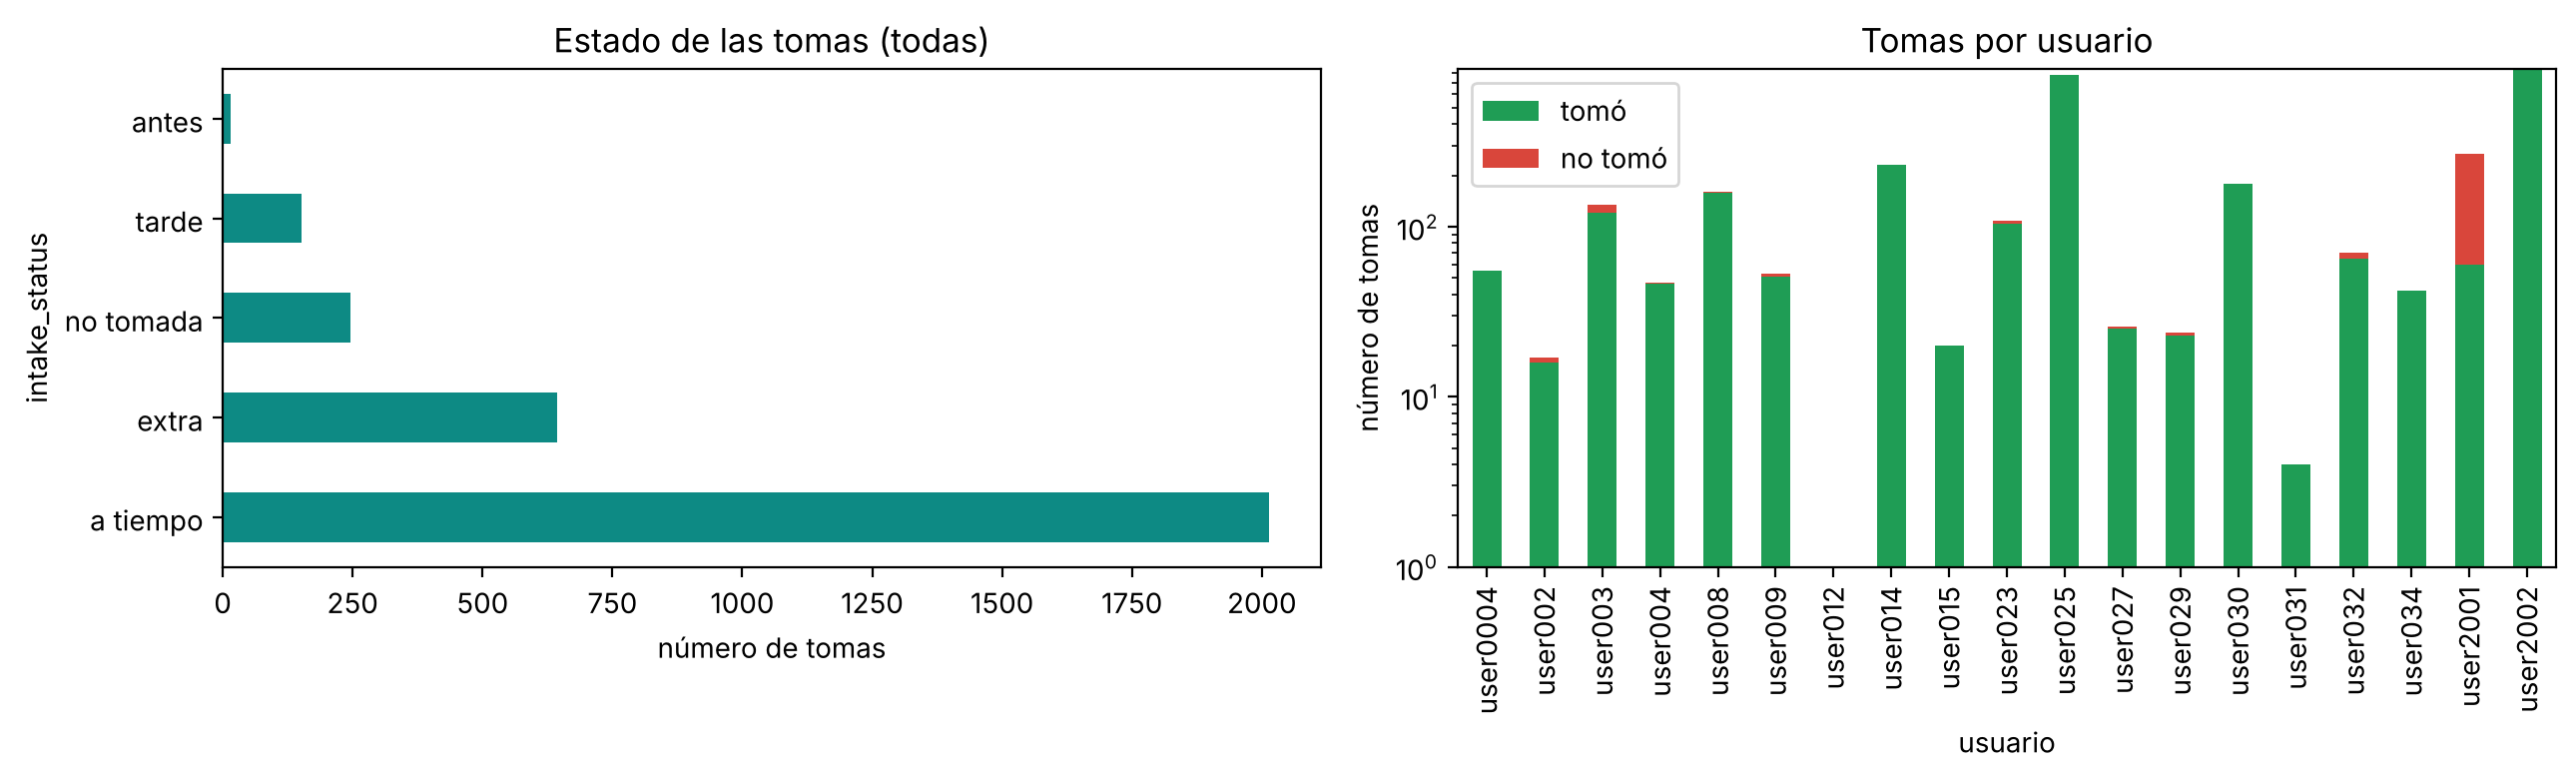

In [5]:
estados = {0: "a tiempo", 1: "antes", 2: "tarde", 3: "omitida", 4: "sin calcular", 5: "extra", 6: "no tomada",
           7: "a tiempo (editada)", 8: "antes (editada)", 9: "tarde (editada)", 10: "omitida (editada)"}
todas_tomas = pd.concat([t.assign(usuario=u) for u, (t, s) in datos.items()])
cuenta = todas_tomas.intake_status.map(estados).value_counts()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cuenta.plot.barh(ax=ax[0], color="#0d8a84"); ax[0].set_title("Estado de las tomas (todas)"); ax[0].set_xlabel("número de tomas")
r = resumen[resumen.tomas > 0].set_index("usuario")[["tomó", "no tomó"]]
r.plot.bar(ax=ax[1], stacked=True, color=["#1f9d55", "#d9463b"]); ax[1].set_title("Tomas por usuario"); ax[1].set_ylabel("número de tomas")
ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

Casi todas las tomas están marcadas como **tomadas**. Los casos de “no tomó” se concentran en un solo participante
(`user2001`), y eso será importante al evaluar el modelo.

## 4. Segmentación de eventos
Se replica el preprocesamiento del código de DoseMate (`data_proc_dosemate.py` y `common_chunks.py`):
1. Un **evento** es un bloque de lecturas separado del siguiente por más de 11 s.
2. Se descarta si falta el acelerómetro o el giroscopio, si dura menos de 10 s o si no se grabó a 26 Hz.
3. Se interpola a una rejilla uniforme de 26 Hz y se **remuestrea a 15 Hz**.
4. La etiqueta (`took_pill`) es la de la toma programada más cercana al inicio del evento.

In [6]:
HZ_ORIGINAL, HZ = 26, 15

def segmentar(tomas, sensores, usuario):
    if len(sensores) == 0:
        return []
    s = sensores.sort_values("time").reset_index(drop=True).copy()
    s["bloque"] = (s["time"].diff().dt.total_seconds() > 11).astype(int).cumsum()
    s["ms"] = s["time"].astype("int64") // 10**6
    eventos = []
    for _, b in s.groupby("bloque"):
        acc, gir = b[b.sensor_type == 0], b[b.sensor_type == 1]
        if len(acc) < 2 or len(gir) < 2 or (b.time.max() - b.time.min()).total_seconds() < 10:
            continue
        t0, t1 = max(acc.ms.min(), gir.ms.min()), min(acc.ms.max(), gir.ms.max())
        n = min(((acc.ms >= t0) & (acc.ms <= t1)).sum(), ((gir.ms >= t0) & (gir.ms <= t1)).sum())
        if (round(n / ((t1 - t0) / 1000)) != HZ_ORIGINAL
                or round(len(acc) / ((acc.ms.max() - acc.ms.min()) / 1000)) != HZ_ORIGINAL
                or round(len(gir) / ((gir.ms.max() - gir.ms.min()) / 1000)) != HZ_ORIGINAL):
            continue
        tt = np.linspace(t0, t1, int(round(HZ_ORIGINAL * (t1 - t0) / 1000)))
        X = np.stack([np.interp(tt, acc.ms, acc[k]) for k in "xyz"] + [np.interp(tt, gir.ms, gir[k]) for k in "xyz"], axis=1)
        X = signal.resample_poly(X, HZ, HZ_ORIGINAL, axis=0)
        inicio = pd.to_datetime(t0, unit="ms")
        k = (tomas.time - inicio).abs().idxmin()
        eventos.append({"usuario": usuario, "inicio": inicio, "X": X, "tomo": bool(tomas.loc[k, "took_pill"])})
    return eventos

eventos = [e for u, (t, s) in datos.items() for e in segmentar(t, s, u)]
ev = pd.DataFrame([{k: v for k, v in e.items() if k != "X"} | {"muestras": len(e["X"])} for e in eventos])
print(f"Eventos: {len(ev)} · tomó: {ev.tomo.sum()} · no tomó: {(~ev.tomo).sum()} · usuarios con eventos: {ev.usuario.nunique()}")
print(f"Duración: {ev.muestras.min() / HZ:.1f}–{ev.muestras.max() / HZ:.1f} s (mediana {ev.muestras.median() / HZ:.1f} s)")
print("Artículo DoseMate: 1,154 eventos candidatos, 185 negativos, de unos 19 s.")
ev.groupby("usuario").tomo.agg(eventos="size", tomó="sum").assign(**{"no tomó": lambda d: d.eventos - d["tomó"]})

Eventos: 1160 · tomó: 975 · no tomó: 185 · usuarios con eventos: 14
Duración: 18.9–19.5 s (mediana 19.1 s)
Artículo DoseMate: 1,154 eventos candidatos, 185 negativos, de unos 19 s.


,eventos,tomó,no tomó
usuario,,,
user002,18,18,0
user003,129,115,14
user004,48,48,0
user008,156,155,1
user009,61,61,0
user012,1,1,0
user014,148,148,0
user015,15,15,0
user023,3,3,0


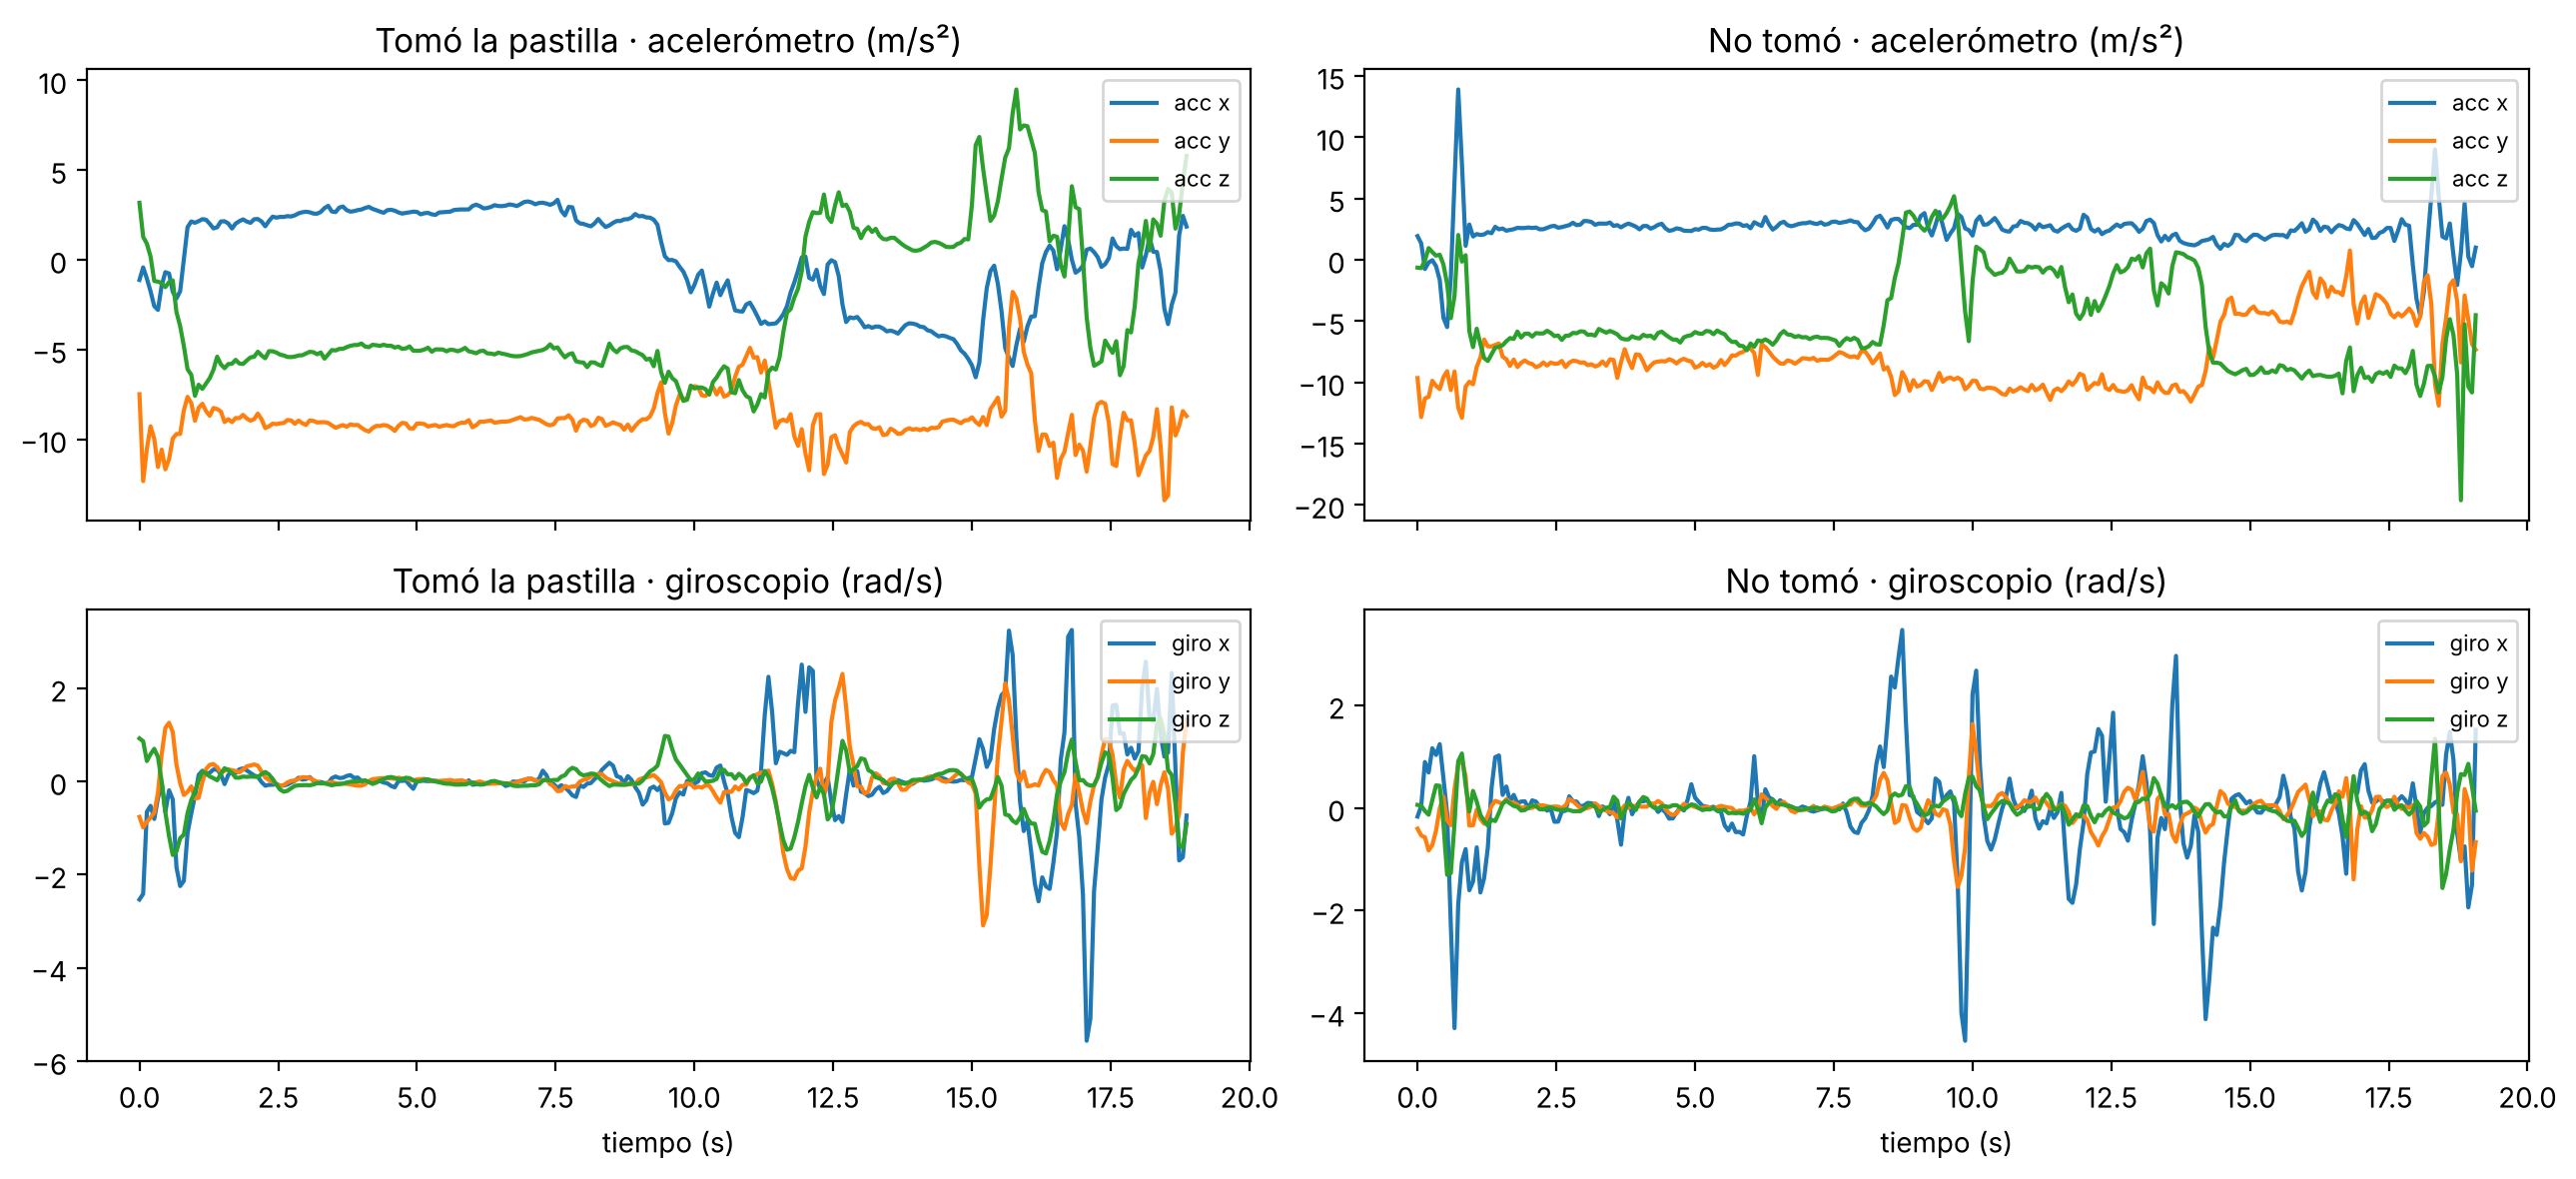

In [7]:
# Un evento positivo y uno negativo, del mismo usuario
pos = next(e for e in eventos if e["usuario"] == "user2001" and e["tomo"])
neg = next(e for e in eventos if e["usuario"] == "user2001" and not e["tomo"])
fig, ax = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for col, (e, titulo) in enumerate([(pos, "Tomó la pastilla"), (neg, "No tomó")]):
    t = np.arange(len(e["X"])) / HZ
    for i, eje in enumerate("xyz"):
        ax[0, col].plot(t, e["X"][:, i], label=f"acc {eje}")
        ax[1, col].plot(t, e["X"][:, 3 + i], label=f"giro {eje}")
    ax[0, col].set_title(f"{titulo} · acelerómetro (m/s²)"); ax[1, col].set_title(f"{titulo} · giroscopio (rad/s)")
    ax[1, col].set_xlabel("tiempo (s)")
    ax[0, col].legend(loc="upper right", fontsize=8); ax[1, col].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

### Tensores de entrada
Se usan **9 canales**, igual que `dosemate_data.py`: los 6 ejes crudos más el acelerómetro filtrado con un
Butterworth de orden 1, pasa-altas de 0.2 Hz y pasa-bajas de 2 Hz. Cada evento se recorta a **18 s (270 muestras)**,
el `FRAME_SECONDS` del código original.

In [8]:
VENTANA = 18 * HZ   # 270 muestras

def filtrar_acc(X):
    b1, a1 = signal.butter(1, 0.2 / (HZ / 2), btype="high")
    b2, a2 = signal.butter(1, 2.0 / (HZ / 2), btype="low")
    return signal.filtfilt(b2, a2, signal.filtfilt(b1, a1, X[:, :3], axis=0), axis=0)

X = np.stack([np.concatenate([e["X"][:VENTANA], filtrar_acc(e["X"])[:VENTANA]], axis=1) for e in eventos]).astype("float32")
y = np.array([int(e["tomo"]) for e in eventos])
grupos = np.array([e["usuario"] for e in eventos])
print("X:", X.shape, "(eventos, muestras, canales) · y:", np.bincount(y), "(no tomó, tomó)")

X: (1160, 270, 9) (eventos, muestras, canales) · y: [185 975] (no tomó, tomó)


## 5. Modelo CNN-LSTM
- Las **convoluciones 1D** detectan patrones locales del movimiento, como levantar la mano, girar la muñeca o bajarla.
- La **LSTM** aprende el orden en que ocurren esos patrones.
- La salida es **P(tomó)**, entre 0 y 1.

Como hay muchos más positivos que negativos, el entrenamiento usa **pesos por clase**. La normalización por canal se
calcula solo con los datos de entrenamiento de cada partición.

In [9]:
def crear_cnn_lstm(muestras=VENTANA, canales=X.shape[2]):
    entrada = keras.Input(shape=(muestras, canales))
    h = layers.Conv1D(32, 7, padding="same")(entrada); h = layers.BatchNormalization()(h); h = layers.ReLU()(h)
    h = layers.MaxPooling1D(2)(h)
    h = layers.Conv1D(64, 5, padding="same")(h); h = layers.BatchNormalization()(h); h = layers.ReLU()(h)
    h = layers.MaxPooling1D(2)(h)
    h = layers.Dropout(0.3)(h)
    h = layers.LSTM(64)(h)
    h = layers.Dropout(0.3)(h)
    salida = layers.Dense(1, activation="sigmoid")(h)
    modelo = keras.Model(entrada, salida, name="cnn_lstm")
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return modelo

crear_cnn_lstm().summary()

Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 270, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 270, 32)        │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 270, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 270, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 135, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 135, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 135, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 135, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 67, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 67, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,825 (179.00 KB)

 Trainable params: 45,633 (178.25 KB)

 Non-trainable params: 192 (768.00 B)

In [10]:
EPOCAS, LOTE = 25, 32

def entrenar_y_predecir(X_ent, y_ent, X_prueba):
    media, desv = X_ent.mean(axis=(0, 1)), X_ent.std(axis=(0, 1)) + 1e-6
    pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_ent) if len(np.unique(y_ent)) == 2 else [1, 1]
    modelo = crear_cnn_lstm()
    modelo.fit((X_ent - media) / desv, y_ent, epochs=EPOCAS, batch_size=LOTE, verbose=0,
               class_weight={0: pesos[0], 1: pesos[1]})
    return modelo.predict((X_prueba - media) / desv, verbose=0).ravel()

def metricas(y_real, p, umbral=0.5):
    pred = (p >= umbral).astype(int)
    return {"exactitud balanceada": balanced_accuracy_score(y_real, pred), "F1": f1_score(y_real, pred),
            "AUC": roc_auc_score(y_real, p), "sensibilidad": recall_score(y_real, pred),
            "especificidad": recall_score(y_real, pred, pos_label=0)}

## 6. Evaluación
### 6.1 Partición aleatoria (5 particiones estratificadas)
Se mezclan eventos de todos los usuarios, así que **la misma persona aparece en entrenamiento y en prueba**. Es lo más
parecido a la partición aleatoria del artículo, aunque aquí no se agregan los datasets abiertos de otras actividades.

In [11]:
t0 = time.time()
p_aleatoria = np.zeros(len(y))
for ent, prueba in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(X, y):
    p_aleatoria[prueba] = entrenar_y_predecir(X[ent], y[ent], X[prueba])
res_aleatoria = metricas(y, p_aleatoria)
print(f"Partición aleatoria · {time.time() - t0:.0f} s")
pd.Series(res_aleatoria).round(3)

Partición aleatoria · 99 s


exactitud balanceada    0.832
F1                      0.931
AUC                     0.914
sensibilidad            0.913
especificidad           0.751
dtype: float64

### 6.2 Leave-one-subject-out (LOSO)
En cada vuelta se deja fuera a **un participante completo** y se entrena con los demás. Mide lo que importa para
MediTrack: qué tan bien funciona el modelo con **una persona que nunca vio**. Las métricas se calculan juntando las
predicciones de todas las vueltas.

In [12]:
t0 = time.time()
p_loso = np.zeros(len(y))
for ent, prueba in LeaveOneGroupOut().split(X, y, grupos):
    p_loso[prueba] = entrenar_y_predecir(X[ent], y[ent], X[prueba])
res_loso = metricas(y, p_loso)
print(f"LOSO · {len(np.unique(grupos))} vueltas · {time.time() - t0:.0f} s")
pd.Series(res_loso).round(3)

LOSO · 14 vueltas · 375 s


exactitud balanceada    0.528
F1                      0.852
AUC                     0.380
sensibilidad            0.855
especificidad           0.200
dtype: float64

In [13]:
por_usuario = (pd.DataFrame({"usuario": grupos, "y": y, "p": p_loso})
               .groupby("usuario")
               .apply(lambda d: pd.Series({"eventos": len(d), "no tomó": int((d.y == 0).sum()),
                                           "aciertos": ((d.p >= 0.5).astype(int) == d.y).mean()}))
               .sort_values("eventos", ascending=False))
por_usuario.round(3)

,eventos,no tomó,aciertos
usuario,,,
user2001,268.0,167.0,0.466
user025,180.0,1.0,0.994
user008,156.0,1.0,0.897
user014,148.0,0.0,0.865
user003,129.0,14.0,0.248
user030,122.0,1.0,0.984
user009,61.0,0.0,0.934
user004,48.0,0.0,0.979
user002,18.0,0.0,0.944


### 6.3 ¿Por qué baja tanto en LOSO?
El AUC calculado juntando todas las vueltas compara probabilidades de **personas distintas**, y 167 de los 185
negativos son de un solo participante (`user2001`). Una medida más justa es el **AUC dentro de cada persona** que
tiene eventos de ambas clases.

In [14]:
for u in ["user2001", "user003"]:
    m = grupos == u
    print(f"{u}: {m.sum()} eventos ({(y[m] == 0).sum()} no tomó) · AUC dentro del usuario (LOSO) = {roc_auc_score(y[m], p_loso[m]):.3f}")

user2001: 268 eventos (167 no tomó) · AUC dentro del usuario (LOSO) = 0.672
user003: 129 eventos (14 no tomó) · AUC dentro del usuario (LOSO) = 0.496


### 6.4 Personalización: ¿ayudan unos días de datos de la propia persona?
En la práctica, MediTrack puede pedir al usuario que confirme a mano sus primeras tomas para ajustar el modelo. Aquí se
simula: para `user2001` y `user003` se entrena con **todos los demás participantes más 4/5 de sus propios eventos**, y
se prueba con el 1/5 restante (5 particiones estratificadas dentro del usuario).

In [15]:
t0 = time.time()
p_pers = np.full(len(y), np.nan)
for u in ["user2001", "user003"]:
    idx_u = np.where(grupos == u)[0]
    otros = np.where(grupos != u)[0]
    for ent_u, prueba_u in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(idx_u, y[idx_u]):
        ent = np.concatenate([otros, idx_u[ent_u]])
        p_pers[idx_u[prueba_u]] = entrenar_y_predecir(X[ent], y[ent], X[idx_u[prueba_u]])
print(f"Personalización · {time.time() - t0:.0f} s")
comparacion = []
for u in ["user2001", "user003"]:
    m = grupos == u
    for nombre, p in [("LOSO (persona nueva)", p_loso), ("personalizado", p_pers)]:
        comparacion.append({"usuario": u, "modelo": nombre} | metricas(y[m], p[m]))
pd.DataFrame(comparacion).round(3)

Personalización · 292 s


,usuario,modelo,exactitud balanceada,F1,AUC,sensibilidad,especificidad
0,user2001,LOSO (persona nueva),0.566,0.578,0.672,0.970,0.162
1,user2001,personalizado,0.653,0.524,0.704,0.426,0.880
2,user003,LOSO (persona nueva),0.453,0.312,0.496,0.191,0.714
3,user003,personalizado,0.520,0.860,0.525,0.826,0.214


## 7. Comparación
### 7.1 Línea base: características simples + Random Forest (LOSO)
Para saber si el modelo profundo aporta, se compara con un Random Forest entrenado sobre estadísticas por canal
(media, desviación, mínimo, máximo y energía), con la misma validación LOSO.

In [16]:
def caracteristicas(X):
    return np.concatenate([X.mean(1), X.std(1), X.min(1), X.max(1), (X ** 2).mean(1)], axis=1)

F = caracteristicas(X)
p_rf = np.zeros(len(y))
for ent, prueba in LeaveOneGroupOut().split(F, y, grupos):
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEMILLA, n_jobs=-1)
    p_rf[prueba] = rf.fit(F[ent], y[ent]).predict_proba(F[prueba])[:, 1]
res_rf = metricas(y, p_rf)

tabla = pd.DataFrame({"CNN-LSTM · partición aleatoria": res_aleatoria, "CNN-LSTM · LOSO": res_loso,
                      "Random Forest · LOSO": res_rf}).T
tabla.loc["DoseMate (artículo) · aprendizaje profundo"] = {"exactitud balanceada": 0.95, "F1": 0.962}
tabla.round(3)

,exactitud balanceada,F1,AUC,sensibilidad,especificidad
CNN-LSTM · partición aleatoria,0.832,0.931,0.914,0.913,0.751
CNN-LSTM · LOSO,0.528,0.852,0.380,0.855,0.200
Random Forest · LOSO,0.483,0.894,0.192,0.961,0.005
DoseMate (artículo) · aprendizaje profundo,0.950,0.962,NaN,NaN,NaN


**Cómo leer la tabla:** la fila de DoseMate son los valores **publicados** por los autores (exactitud balanceada de 95 %
y F1 promedio de 96.2 % para aprendizaje profundo). No son directamente comparables, porque ellos entrenaron también con
datasets abiertos de otras actividades de muñeca como negativos y usaron otra partición. Las filas de arriba son las que
calcula este notebook.

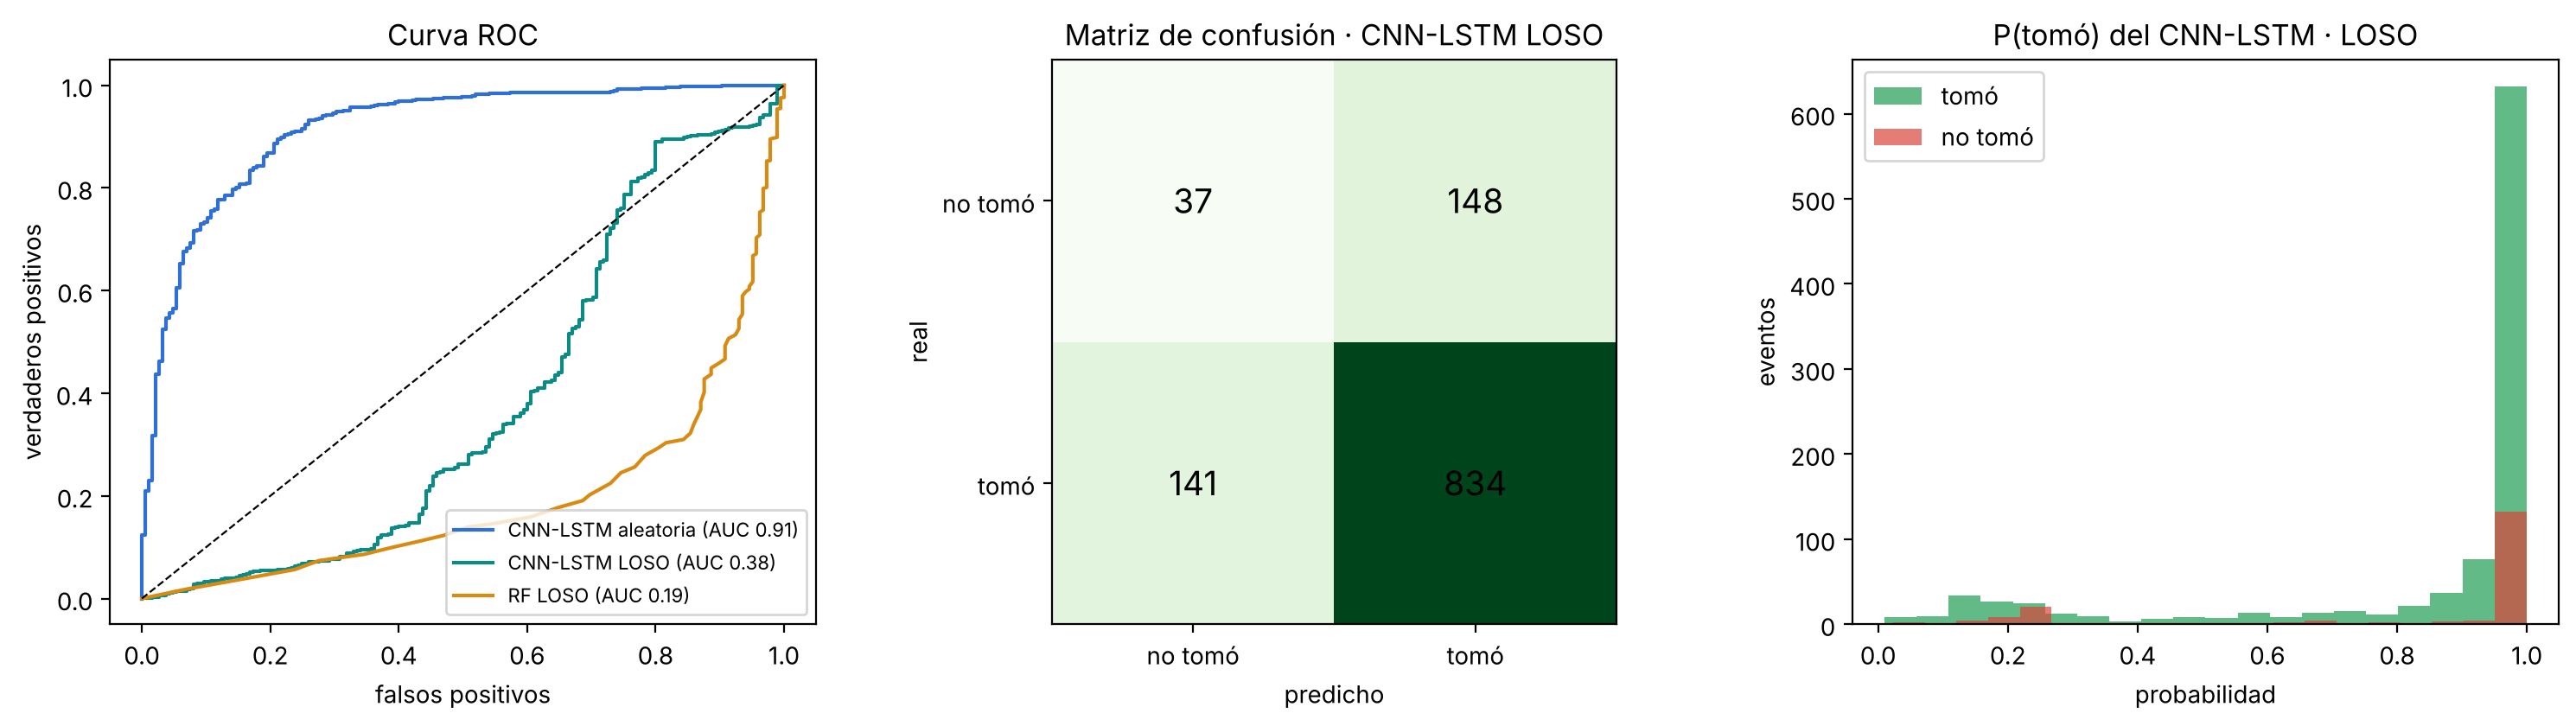

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for nombre, p, c in [("CNN-LSTM aleatoria", p_aleatoria, "#2f6fd6"), ("CNN-LSTM LOSO", p_loso, "#0d8a84"), ("RF LOSO", p_rf, "#d98a12")]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y, p):.2f})", color=c)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title("Curva ROC"); ax[0].set_xlabel("falsos positivos"); ax[0].set_ylabel("verdaderos positivos"); ax[0].legend(fontsize=8)
cm = confusion_matrix(y, (p_loso >= 0.5).astype(int))
ax[1].imshow(cm, cmap="Greens"); ax[1].set_xticks([0, 1], ["no tomó", "tomó"]); ax[1].set_yticks([0, 1], ["no tomó", "tomó"])
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax[1].set_title("Matriz de confusión · CNN-LSTM LOSO"); ax[1].set_xlabel("predicho"); ax[1].set_ylabel("real")
ax[2].hist(p_loso[y == 1], bins=20, alpha=0.7, label="tomó", color="#1f9d55")
ax[2].hist(p_loso[y == 0], bins=20, alpha=0.7, label="no tomó", color="#d9463b")
ax[2].set_title("P(tomó) del CNN-LSTM · LOSO"); ax[2].set_xlabel("probabilidad"); ax[2].set_ylabel("eventos"); ax[2].legend()
plt.tight_layout(); plt.show()

## 8. Fusión de evidencias de MediTrack
MediTrack no decide solo con el gesto. Cada evidencia observada, con valor $v_e \in [0,1]$ y peso $w_e$, suma
*log-odds*:

$$P(\text{tomó}) = \sigma\Big(b + \sum_{e} w_e\,(2v_e - 1)\Big),\qquad b = -0.35$$

| evidencia | peso inicial |
|---|---|
| gesto mano-boca (IMU) | 2.2 |
| secuencia abrir → boca → beber | 1.2 |
| etiqueta NFC del frasco | 1.6 |
| ventana de la toma y rutina | 0.5 |

**Decisión:** P ≥ 0.85 confirma · 0.50 ≤ P < 0.85 pregunta · P < 0.50 espera. Los pesos son la propuesta del
documento técnico; con datos de un piloto se aprenderían.

In [18]:
PESOS = {"gesto": 2.2, "secuencia": 1.2, "nfc": 1.6, "horario": 0.5}
SESGO, UMBRAL_CONFIRMAR, UMBRAL_PREGUNTAR = -0.35, 0.85, 0.50

def fusion(**evidencias):
    x = SESGO + sum(PESOS[k] * (2 * v - 1) for k, v in evidencias.items() if v is not None)
    return 1 / (1 + np.exp(-x))

def decision(p):
    return np.where(p >= UMBRAL_CONFIRMAR, "confirmar", np.where(p >= UMBRAL_PREGUNTAR, "preguntar", "esperar"))

ejemplos = pd.DataFrame([
    {"caso": "toma completa", "gesto": 0.90, "secuencia": 0.85, "nfc": None, "horario": 0.75},
    {"caso": "solo bebe agua", "gesto": 0.70, "secuencia": 0.40, "nfc": None, "horario": 0.75},
    {"caso": "solo NFC (reloj sin IMU)", "gesto": None, "secuencia": None, "nfc": 1.0, "horario": 0.75},
    {"caso": "NFC + toma completa", "gesto": 0.90, "secuencia": 0.85, "nfc": 1.0, "horario": 0.75},
    {"caso": "escena del video (Rafael)", "gesto": 0.91, "secuencia": 0.86, "nfc": None, "horario": 0.75},
])
ejemplos["P(tomó)"] = [fusion(**{k: r[k] for k in PESOS if pd.notna(r[k])}) for _, r in ejemplos.iterrows()]
ejemplos["decisión"] = decision(ejemplos["P(tomó)"].values)
ejemplos.round(3)

,caso,gesto,secuencia,nfc,horario,P(tomó),decisión
0,toma completa,0.90,0.85,NaN,0.75,0.924,confirmar
1,solo bebe agua,0.70,0.40,NaN,0.75,0.632,preguntar
2,solo NFC (reloj sin IMU),NaN,NaN,1.0,0.75,0.818,preguntar
3,NFC + toma completa,0.90,0.85,1.0,0.75,0.984,confirmar
4,escena del video (Rafael),0.91,0.86,NaN,0.75,0.929,confirmar


### 8.1 Fusión con las predicciones reales del modelo
Ahora se usa la **P(tomó) del CNN-LSTM en LOSO** como evidencia del gesto, con el horario en 0.75 para todos los eventos
(en DoseMate todos ocurren en la ventana de la toma). DoseMate no mide la secuencia por separado, así que esa evidencia
no se incluye. Se comparan dos escenarios:
- **sin NFC:** solo gesto y horario;
- **con NFC:** el paciente además toca la etiqueta del frasco. Este escenario es ilustrativo: en DoseMate el toque NFC
  iniciaba la grabación en todos los eventos, así que ahí no distingue positivos de negativos.

In [19]:
def tabla_decisiones(p_fusion):
    d = pd.crosstab(pd.Series(np.where(y == 1, "tomó", "no tomó"), name="real"),
                    pd.Series(decision(p_fusion), name="decisión"), normalize="index") * 100
    return d.reindex(columns=["confirmar", "preguntar", "esperar"], fill_value=0).round(1)

p_sin_nfc = fusion(gesto=p_loso, horario=0.75)
p_con_nfc = fusion(gesto=p_loso, horario=0.75, nfc=1.0)
print("Modelo LOSO · sin NFC (% de cada fila)"); display(tabla_decisiones(p_sin_nfc))
print("Modelo LOSO · con NFC (% de cada fila)"); display(tabla_decisiones(p_con_nfc))

Modelo LOSO · sin NFC (% de cada fila)


decisión,confirmar,preguntar,esperar
real,,,
no tomó,72.4,7.6,20.0
tomó,70.9,14.6,14.6


Modelo LOSO · con NFC (% de cada fila)


decisión,confirmar,preguntar,esperar
real,,,
no tomó,80.0,17.8,2.2
tomó,84.8,9.9,5.2


In [20]:
# Las mismas decisiones para user2001, comparando el modelo de persona nueva con el personalizado
m = grupos == "user2001"
for nombre, p in [("LOSO (persona nueva)", p_loso), ("personalizado", p_pers)]:
    pf = fusion(gesto=p[m], horario=0.75)
    d = pd.crosstab(pd.Series(np.where(y[m] == 1, "tomó", "no tomó"), name="real"),
                    pd.Series(decision(pf), name="decisión"), normalize="index") * 100
    print(f"user2001 · {nombre} · sin NFC (% de cada fila)")
    display(d.reindex(columns=["confirmar", "preguntar", "esperar"], fill_value=0).round(1))

user2001 · LOSO (persona nueva) · sin NFC (% de cada fila)


decisión,confirmar,preguntar,esperar
real,,,
no tomó,77.2,6.6,16.2
tomó,96.0,1.0,3.0


user2001 · personalizado · sin NFC (% de cada fila)


decisión,confirmar,preguntar,esperar
real,,,
no tomó,3.0,9.0,88.0
tomó,25.7,14.9,59.4


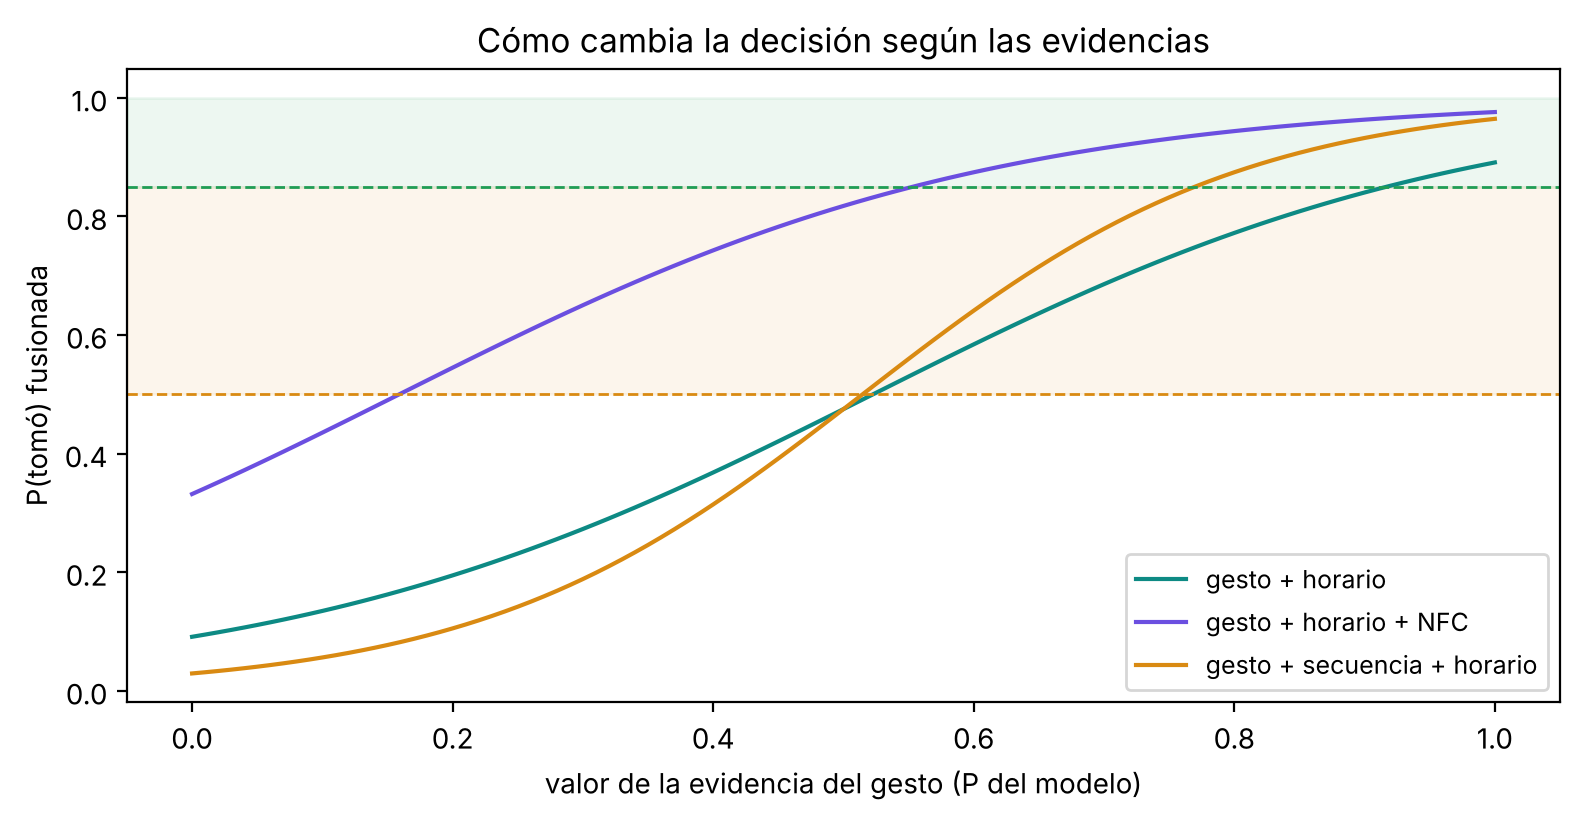

In [21]:
v = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(v, fusion(gesto=v, horario=0.75), label="gesto + horario", color="#0d8a84")
ax.plot(v, fusion(gesto=v, horario=0.75, nfc=1.0), label="gesto + horario + NFC", color="#6b4fe0")
ax.plot(v, fusion(gesto=v, secuencia=v, horario=0.75), label="gesto + secuencia + horario", color="#d98a12")
ax.axhspan(UMBRAL_CONFIRMAR, 1, color="#1f9d55", alpha=0.08); ax.axhspan(UMBRAL_PREGUNTAR, UMBRAL_CONFIRMAR, color="#d98a12", alpha=0.08)
ax.axhline(UMBRAL_CONFIRMAR, color="#1f9d55", lw=1, ls="--"); ax.axhline(UMBRAL_PREGUNTAR, color="#d98a12", lw=1, ls="--")
ax.set_xlabel("valor de la evidencia del gesto (P del modelo)"); ax.set_ylabel("P(tomó) fusionada")
ax.set_title("Cómo cambia la decisión según las evidencias"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 9. Conclusiones

1. **El preprocesamiento replica el del artículo.** Salen **1,160 eventos con 185 negativos** de unos 19 s, contra los
   1,154 eventos con 185 negativos que reporta DoseMate. Los negativos están muy concentrados: 167 son de `user2001`.
2. **Cuando el modelo ya conoce a la persona, funciona razonablemente.** Con la partición aleatoria, donde la misma
   persona aparece en entrenamiento y en prueba, el CNN-LSTM logra **exactitud balanceada 0.832, F1 0.931 y AUC 0.914**.
   Queda por debajo del **0.95 / 0.962 publicado**, que además usó datasets abiertos de otras actividades como negativos.
3. **Con personas nuevas (LOSO) casi no generaliza.** La exactitud balanceada cae a **0.528** y la especificidad a
   **0.200**. El AUC conjunto de **0.380** no es una medida justa, porque mezcla las probabilidades de personas
   distintas. Dentro de cada persona, el AUC es **0.672 en `user2001`** (hay algo de señal) y **0.496 en `user003`**
   (nada). La línea base con Random Forest es peor (exactitud balanceada 0.483). Con estos datos, el gesto por sí solo
   **no basta** para reconocer la toma en alguien que el modelo no ha visto. Hay dos razones: casi todos los negativos
   vienen de una persona, y un “no tomó” en DoseMate es una grabación en la que la persona sí manipuló el frasco, así que
   el movimiento se parece mucho al de una toma.
4. **La personalización ayuda, pero exige ajustar el umbral.** En `user2001`, agregar 4/5 de sus propios eventos sube
   la exactitud balanceada de **0.566 a 0.653**, el AUC de **0.672 a 0.704** y la especificidad de **0.162 a 0.880**.
   A cambio, la sensibilidad baja de **0.970 a 0.426**. El umbral de decisión tiene que calibrarse para cada persona.
5. **Efecto en la fusión de evidencias de MediTrack.**
   - Con el modelo de persona nueva y sin NFC, el sistema confirmaría automáticamente el **72.4 % de los “no tomó”**,
     casi igual que el **70.9 % de las tomas reales**.
   - El NFC no ayuda a distinguirlas, porque en ambos casos se toca el frasco: sube las dos cifras (80.0 % y 84.8 %).
   - Con el modelo personalizado, en `user2001` las falsas confirmaciones bajan a **3.0 %**, pero solo el **25.7 %** de
     las tomas reales se confirma solo. El resto pasa a pregunta o a confirmación manual.

**Qué implica para MediTrack**
- No hay que presentar el 94–95 % de DoseMate como desempeño propio. Lo que mide este notebook con personas nuevas es
  bastante menor.
- El MVP debe apoyarse en la **confirmación manual y el NFC**. El gesto conviene usarlo como evidencia de apoyo que
  reduce preguntas, no como prueba.
- Hace falta una **fase de calibración personal**: las primeras tomas se confirman a mano para ajustar el modelo y el
  umbral de cada usuario.
- Para mejorar el modelo se necesitan **más negativos de muchas personas** (el piloto) y, como hizo DoseMate, datasets
  abiertos de otras actividades de muñeca como negativos.

*Fuente de los datos: Nzeyimana et al. (2024), DoseMate, PMLR 248:566–581. Repositorio sin licencia explícita, usado con
fines académicos y sin redistribuir los datos.*